## 🔧 Cell 1 · Setup

Imports the libraries, defines file paths (creating output folders if missing), and sets the key constants.

- `TARGET` → the column we predict (`use_HO`)
- `PREDICTORS` → weather columns
- `RF_FINAL` / `XGB_FINAL` → final model parameters, chosen on validation
- Helper functions `mae_rmse()` and `report()` for printing model errors

In [24]:
import json
import sys
import importlib
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

DATA_DIR = Path(r"D:\Hass")
DATA_FILE = (DATA_DIR / "Augmented Smart Home with Weather Information"
             / "Augmented Smart Home with Weather Information" / "HomeC_augmented.csv")
CLEAN_DIR = DATA_DIR / "data_clean"   # ملفات بتتولّد من النوتبوك (مش بتترفع على GitHub)
OUT = DATA_DIR / "energy"             # الكود والموديلات والرسومات والـ config
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = CLEAN_DIR / "clean_data_task_2.csv"

TARGET = "use_HO"
PREDICTORS = [
    "temperature", "humidity", "apparentTemperature", "windSpeed",
    "cloudCover", "pressure", "dewPoint", "visibility", "windBearing",
    "precipIntensity", "precipProbability",
]

# باراميترز الموديلات النهائية (اتحددت على الـ validation)
RF_FINAL = dict(n_estimators=300, min_samples_leaf=10, max_depth=15,
                n_jobs=-1, random_state=42)
XGB_FINAL = dict(n_estimators=500, learning_rate=0.03, max_depth=7,
                 subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)


def mae_rmse(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            float(np.sqrt(mean_squared_error(y_true, y_pred))))


def report(name, y_true, y_pred):
    mae, rmse = mae_rmse(y_true, y_pred)
    print(f"{name:34s} MAE={mae:.4f}  RMSE={rmse:.4f}")

## 📥 Cell 2 · Load Raw Data

Reads the HomeC file and keeps only the columns we need (time, target, weather). Prints the shape before and after filtering and the memory size saved.

In [25]:
df_raw = pd.read_csv(DATA_FILE, low_memory=False)

print(f"Raw shape: {df_raw.shape[0]} rows X {df_raw.shape[1]} columns")
print("Original columns:")
print(list(df_raw.columns))

# قايمة بيضاء: لو اسم غلط هيطلع KeyError وده المطلوب
df = df_raw[["time", TARGET] + PREDICTORS].copy()

raw_mb = df_raw.memory_usage(deep=True).sum() / 1e6
df_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"\nFiltered shape: {df.shape[0]} rows X {df.shape[1]} columns")
print(f"Raw size {raw_mb:.2f} MB | Filtered size {df_mb:.2f} MB")

Raw shape: 503910 rows X 42 columns
Original columns:
['Unnamed: 0', 'time', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'temperature', 'humidity', 'visibility', 'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability', 'Furnace', 'Kitchen', 'year', 'month', 'day', 'weekday', 'weekofyear', 'hour', 'minute', 'timing', 'use_HO', 'gen_Sol', 'Car charger [kW]', 'Water heater [kW]', 'Air conditioning [kW]', 'Home Theater [kW]', 'Outdoor lights [kW]', 'microwave [kW]', 'Laundry [kW]', 'Pool Pump [kW]']

Filtered shape: 503910 rows X 13 columns
Raw size 260.05 MB | Filtered size 86.67 MB


## 🔎 Cell 3 · Sanity Checks on the Raw Data

- Checks that the sum of all individual devices correlates with `use_HO`
- Prints statistics for `use_HO` and `gen_Sol`
- Shows sample values from the `time` column to see its format

In [26]:
dev_cols = ["Dishwasher", "Home office", "Fridge", "Wine cellar", "Garage door",
            "Barn", "Well", "Microwave", "Living room", "Furnace", "Kitchen"]

print("corr(sum of devices, use_HO):",
      round(df_raw[dev_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1).corr(
          pd.to_numeric(df_raw["use_HO"], errors="coerce")), 4))

print("\nuse_HO / gen_Sol stats:")
print(df_raw[["use_HO", "gen_Sol"]].describe())

print("\ntime samples:")
print(df_raw["time"].head(3).tolist())
print(df_raw["time"].tail(3).tolist())

corr(sum of devices, use_HO): 0.6562

use_HO / gen_Sol stats:
              use_HO        gen_Sol
count  503910.000000  503910.000000
mean        0.858962       0.076229
std         1.058207       0.128428
min         0.000000       0.000000
25%         0.367667       0.003367
50%         0.562333       0.004283
75%         0.970250       0.083917
max        14.714567       0.613883

time samples:
['2016-01-01 05:00:00', '2016-01-01 05:01:00', '2016-01-01 05:02:00']
['2016-12-16 03:27:00', '2016-12-16 03:28:00', '2016-12-16 03:29:00']


## 👀 Cell 4 · Quick Look

Shows the column types and the first 3 rows of the filtered data.

In [27]:
df.info()
display(df.head(3))

<class 'pandas.DataFrame'>
RangeIndex: 503910 entries, 0 to 503909
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   time                 503910 non-null  str    
 1   use_HO               503910 non-null  float64
 2   temperature          503910 non-null  float64
 3   humidity             503910 non-null  float64
 4   apparentTemperature  503910 non-null  float64
 5   windSpeed            503910 non-null  float64
 6   cloudCover           503910 non-null  float64
 7   pressure             503910 non-null  float64
 8   dewPoint             503910 non-null  float64
 9   visibility           503910 non-null  float64
 10  windBearing          503910 non-null  float64
 11  precipIntensity      503910 non-null  float64
 12  precipProbability    503910 non-null  float64
dtypes: float64(12), str(1)
memory usage: 50.0 MB


,time,use_HO,temperature,humidity,apparentTemperature,windSpeed,cloudCover,pressure,dewPoint,visibility,windBearing,precipIntensity,precipProbability
0,2016-01-01 05:00:00,0.932833,36.14,0.62,29.26,9.18,0.75,1016.91,24.4,10.0,282.0,0.0,0.0
1,2016-01-01 05:01:00,0.934333,36.14,0.62,29.26,9.18,0.75,1016.91,24.4,10.0,282.0,0.0,0.0
2,2016-01-01 05:02:00,0.931817,36.14,0.62,29.26,9.18,0.75,1016.91,24.4,10.0,282.0,0.0,0.0


## ⏱️ Cell 5 · Fix Time & Resample to Hourly

- Converts `time` to a proper datetime (Unix seconds or text)
- Drops rows with invalid time and sorts by time
- Converts all columns to numbers
- Resamples from minute-level to **hourly averages**

In [28]:
# ---------- الوقت ----------
t_num = pd.to_numeric(df["time"], errors="coerce")
if t_num.notna().mean() > 0.9:
    df["time"] = pd.to_datetime(t_num, unit="s")        # Unix seconds
else:
    df["time"] = pd.to_datetime(df["time"], errors="coerce")  # نص عادي

bad_time = df["time"].isna().sum()
df = df.dropna(subset=["time"]).set_index("time").sort_index()
print(f"Rows dropped (bad time): {bad_time}")

# ---------- كل الأعمدة لأرقام ----------
df = df.apply(pd.to_numeric, errors="coerce")

# ---------- من دقيقة لساعة ----------
df = df.resample("1h").mean()

print(df.shape)
print("From:", df.index.min(), " To:", df.index.max())

Rows dropped (bad time): 0
(8399, 12)
From: 2016-01-01 05:00:00  To: 2016-12-16 03:00:00


## 🕳️ Cell 6 · Check Missing Values

Prints the % of nulls per column and checks that the hourly index has **no missing hours**.

In [29]:
null_pct = df.isna().mean().mul(100).round(2).sort_values(ascending=False)

print("Null Percentage:")
print(null_pct[null_pct > 0])

if null_pct.sum() == 0:
    print("No missing values found in the dataset.")

# مفيش ساعات ناقصة في الفهرس؟
expected = pd.date_range(df.index.min(), df.index.max(), freq="1h")
print(f"Expected hours: {len(expected)} | actual: {len(df)} | "
      f"missing: {len(expected.difference(df.index))}")

Null Percentage:
Series([], dtype: float64)
No missing values found in the dataset.
Expected hours: 8399 | actual: 8399 | missing: 0


## 📊 Cell 7 · Distributions & Outliers

Plots a histogram (with KDE) and a boxplot for `use_HO`, `temperature`, `humidity`, and `apparentTemperature`.

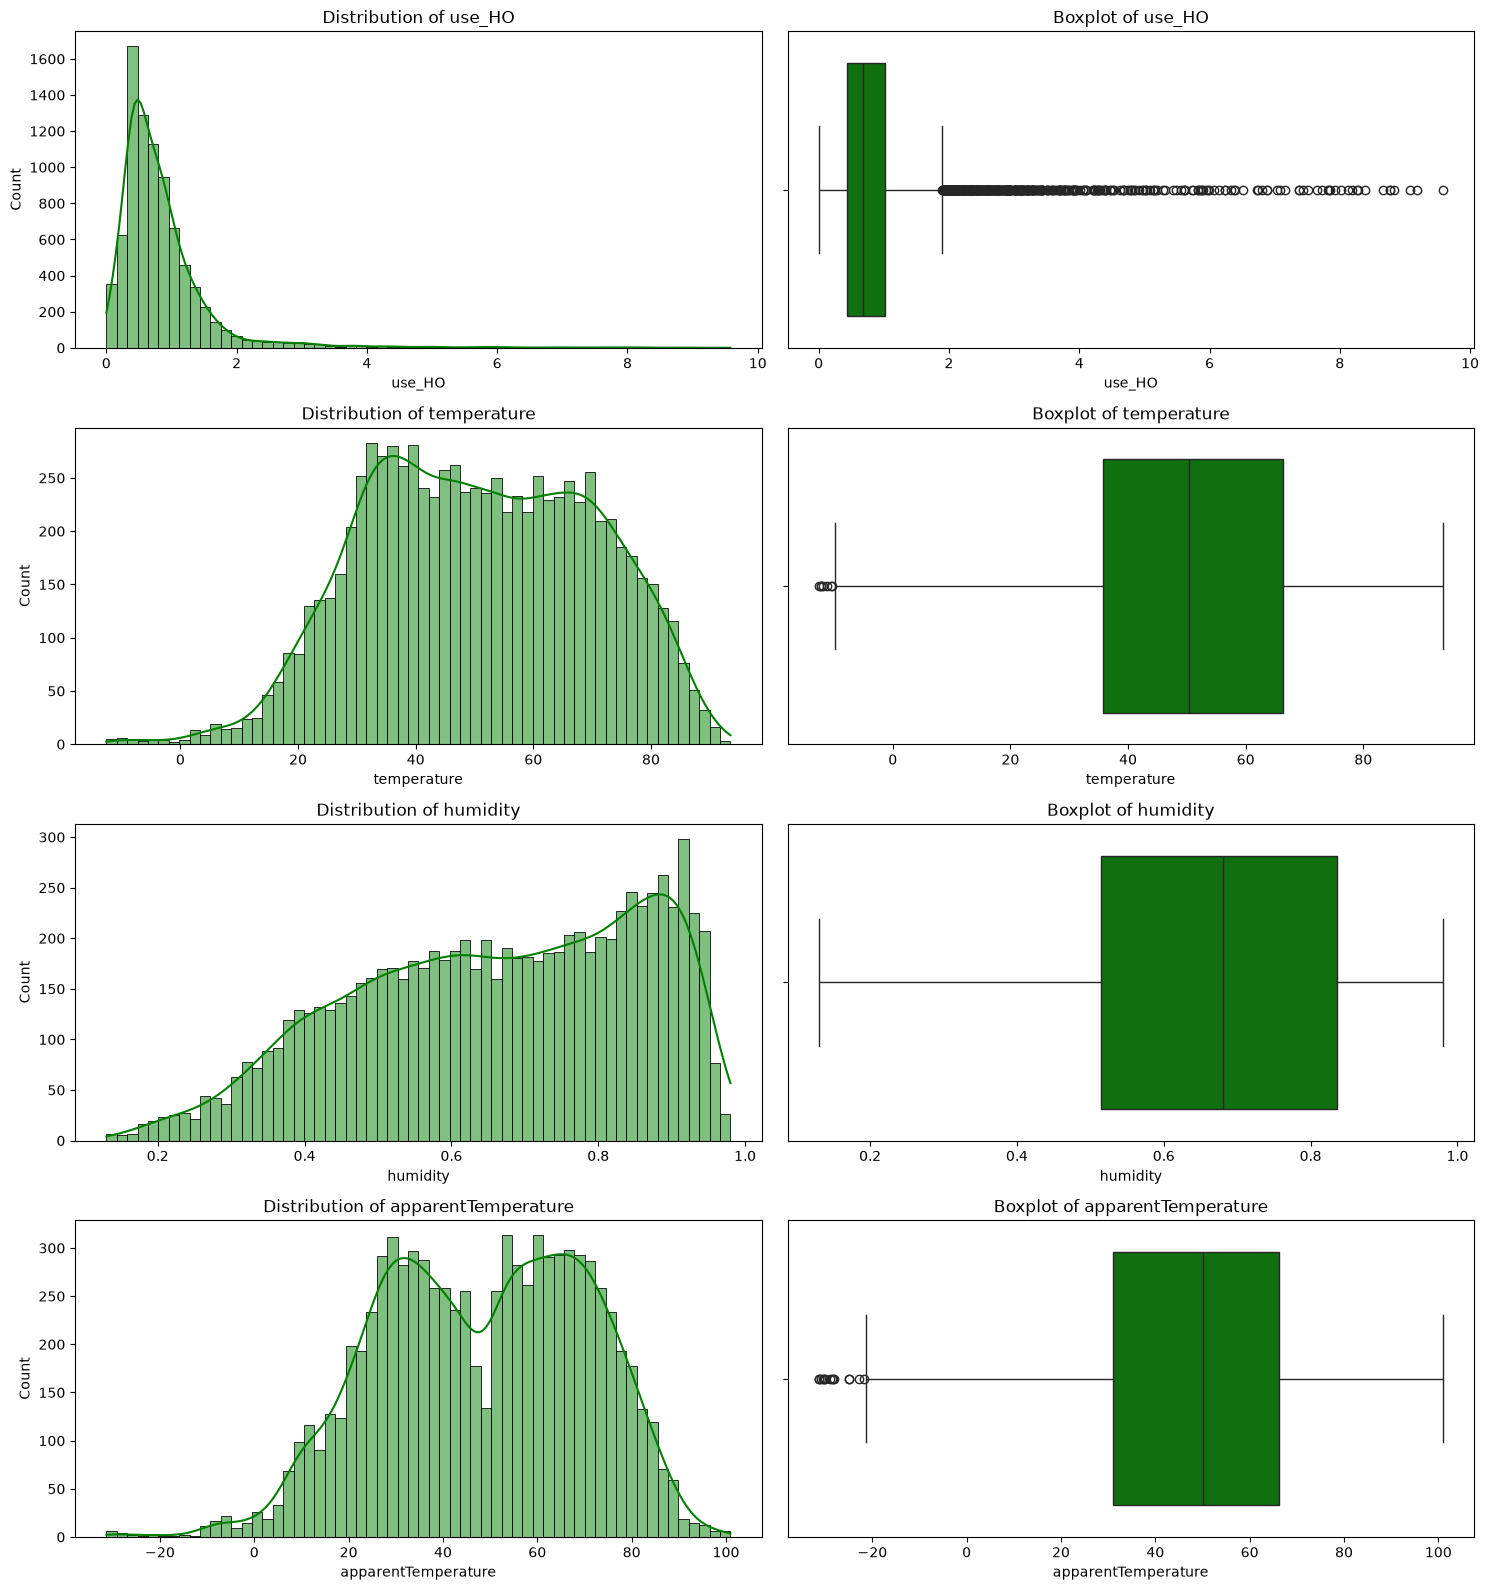

In [30]:
selected_cols = ["use_HO", "temperature", "humidity", "apparentTemperature"]

fig, axes = plt.subplots(len(selected_cols), 2, figsize=(15, 4 * len(selected_cols)))

for i, col in enumerate(selected_cols):
    sns.histplot(data=df, x=col, bins=60, ax=axes[i, 0], color="green", kde=True)
    axes[i, 0].set_title(f"Distribution of {col}")

    sns.boxplot(x=df[col].dropna(), ax=axes[i, 1], color="green")
    axes[i, 1].set_title(f"Boxplot of {col}")

fig.tight_layout()
plt.show()

## 📐 Cell 8 · Normality Check

Prints **skewness** and **kurtosis** for the selected columns and draws a **Q-Q plot** for each to see how far they are from a normal distribution.

use_HO | Skewness: 4.39 (Normal=0) | Kurtosis: 28.99 (Normal=0, excess)
temperature | Skewness: -0.09 (Normal=0) | Kurtosis: -0.67 (Normal=0, excess)
humidity | Skewness: -0.36 (Normal=0) | Kurtosis: -0.84 (Normal=0, excess)
apparentTemperature | Skewness: -0.21 (Normal=0) | Kurtosis: -0.61 (Normal=0, excess)


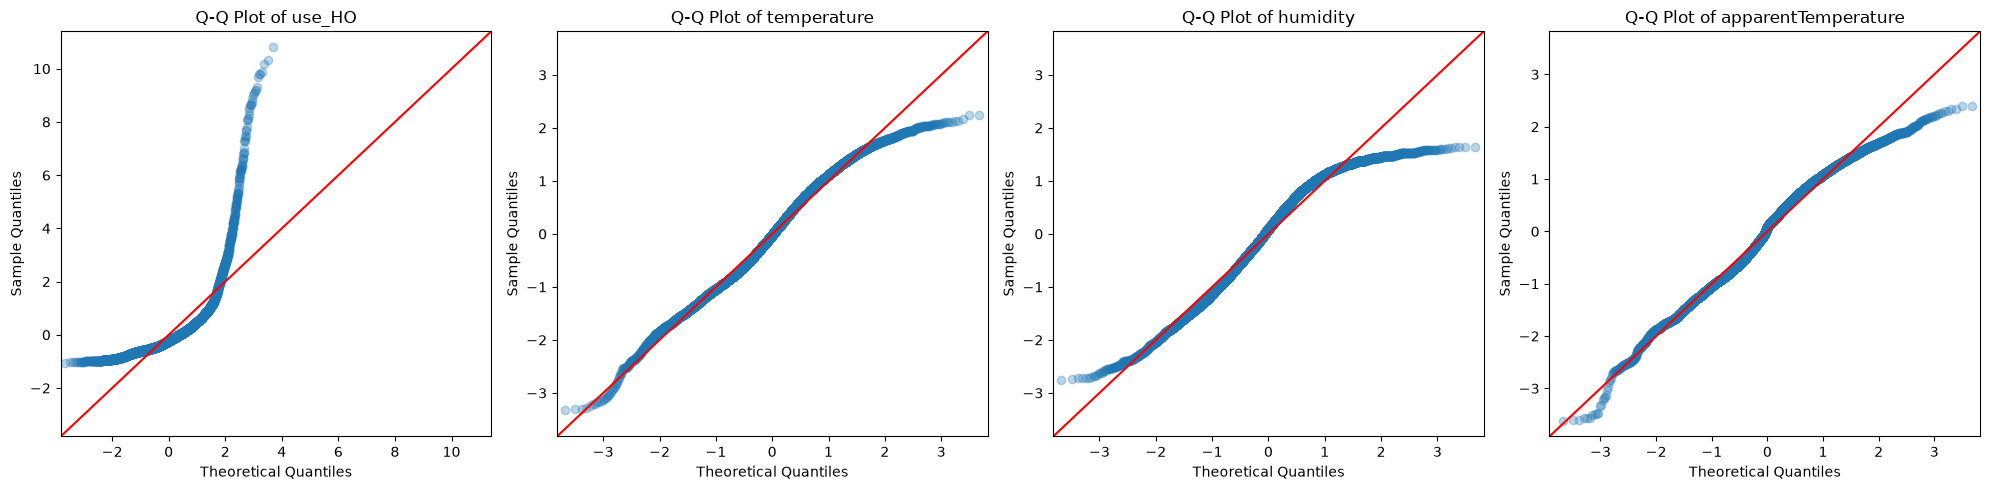

In [31]:
for col in selected_cols:
    series = df[col].dropna()
    if len(series) < 2:
        print(f"{col}: Not enough data.")
        continue
    print(f"{col} | Skewness: {series.skew():.2f} (Normal=0) "
          f"| Kurtosis: {series.kurtosis():.2f} (Normal=0, excess)")

fig, axes = plt.subplots(1, len(selected_cols), figsize=(5 * len(selected_cols), 5))

for ax, col in zip(axes, selected_cols):
    sm.qqplot(df[col].dropna(), line="45", ax=ax, fit=True, alpha=0.3)
    ax.set_title(f"Q-Q Plot of {col}")

fig.tight_layout()
plt.show()

## 🗓️ Cell 9 · Time Features & Save Clean Data

- Adds `hour`, `weekday`, `month`, and `is_weekend`
- Checks for nulls
- 💾 Saves the result as `clean_data_task_2.csv`

In [32]:
df["hour"] = df.index.hour
df["weekday"] = df.index.day_of_week
df["month"] = df.index.month
df["is_weekend"] = (df["weekday"] >= 5).astype(int)

print(df.shape)
print(df.dtypes)
print("Nulls:", int(df.isna().sum().sum()))

df.to_csv(OUTPUT_FILE)      # من غير index=False، عشان الوقت يتحفظ
print(f"\nCleaned data saved to: {OUTPUT_FILE}")

(8399, 16)
use_HO                 float64
temperature            float64
humidity               float64
apparentTemperature    float64
windSpeed              float64
cloudCover             float64
pressure               float64
dewPoint               float64
visibility             float64
windBearing            float64
precipIntensity        float64
precipProbability      float64
hour                     int32
weekday                  int32
month                    int32
is_weekend               int64
dtype: object
Nulls: 0

Cleaned data saved to: D:\Hass\data_clean\clean_data_task_2.csv


## 🛠️ Cell 10 · Lag & Rolling Features

Adds past-value features for the target:

- **Lags** → value 1, 2, 24, and 168 hours ago
- **Rolling means** → average of the last 24 and 168 hours (shifted so the current hour is not included)

Drops the first 168 hours since they have no history.

In [33]:
feat = df.copy()      # df يفضل نضيف، وده اللي اتحفظ في clean_data_task_2.csv

for lag in [1, 2, 24, 168]:
    feat[f"lag_{lag}"] = feat[TARGET].shift(lag)

# shift(1) قبل rolling عشان قيمة الساعة الحالية ماتدخلش في المتوسط
feat["roll_24"] = feat[TARGET].shift(1).rolling(24).mean()
feat["roll_168"] = feat[TARGET].shift(1).rolling(168).mean()

df_model = feat.dropna().copy()     # أول 168 ساعة هتروح (مفيش لها ماضي)
print(df_model.shape)

(8231, 22)


## ✂️ Cell 11 · Train / Validation / Test Split

Splits the data **in time order**: 70% train, 15% validation, 15% test. Prints the size and date range of each part.

In [34]:
n = len(df_model)
train = df_model.iloc[: int(n * 0.70)]
val   = df_model.iloc[int(n * 0.70): int(n * 0.85)]
test  = df_model.iloc[int(n * 0.85):]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(part):5d} rows | {part.index.min()} -> {part.index.max()}")

train:  5761 rows | 2016-01-08 05:00:00 -> 2016-09-04 05:00:00
val  :  1235 rows | 2016-09-04 06:00:00 -> 2016-10-25 16:00:00
test :  1235 rows | 2016-10-25 17:00:00 -> 2016-12-16 03:00:00


## 📏 Cell 12 · Simple Baselines

Scores two naive forecasts on the test set to set the bar the models must beat:

- Same hour **yesterday**
- Same hour **last week**

In [35]:
report("Baseline: same hour yesterday", test[TARGET], test["lag_24"])
report("Baseline: same hour last week", test[TARGET], test["lag_168"])

Baseline: same hour yesterday      MAE=0.3743  RMSE=0.5764
Baseline: same hour last week      MAE=0.3957  RMSE=0.5962


## 🌲 Cell 13 · First Models

Trains **Random Forest** and **XGBoost** on the training set and compares them with the yesterday-baseline on the **validation** set.

In [36]:
FEATURES = [c for c in df_model.columns if c not in [TARGET, "month"]]

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]

# الـ baseline على نفس الـ validation للمقارنة العادلة
report("Baseline yesterday (val)", y_val, val["lag_24"])

rf = RandomForestRegressor(
    n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42
).fit(X_train, y_train)
report("Random Forest (val)", y_val, rf.predict(X_val))

xgb = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42,
).fit(X_train, y_train)
report("XGBoost (val)", y_val, xgb.predict(X_val))

Baseline yesterday (val)           MAE=0.3637  RMSE=0.6985
Random Forest (val)                MAE=0.2208  RMSE=0.4018
XGBoost (val)                      MAE=0.2277  RMSE=0.4016


## 🎛️ Cell 14 · Hyperparameter Search

Tries a grid of settings for both models (RF: leaf size × depth, XGB: depth × learning rate), scores each on validation, and prints a table sorted by MAE.

In [37]:
rows = []

for leaf, depth in product([3, 5, 10], [None, 15]):
    p = RandomForestRegressor(
        n_estimators=300, min_samples_leaf=leaf, max_depth=depth,
        n_jobs=-1, random_state=42,
    ).fit(X_train, y_train).predict(X_val)
    mae, rmse = mae_rmse(y_val, p)
    rows.append({"model": "RF", "params": f"leaf={leaf}, depth={depth}",
                 "MAE": mae, "RMSE": rmse})

for depth, lr in product([3, 5, 7], [0.03, 0.05]):
    p = XGBRegressor(
        n_estimators=500, learning_rate=lr, max_depth=depth,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42,
    ).fit(X_train, y_train).predict(X_val)
    mae, rmse = mae_rmse(y_val, p)
    rows.append({"model": "XGB", "params": f"depth={depth}, lr={lr}",
                 "MAE": mae, "RMSE": rmse})

res = pd.DataFrame(rows).sort_values("MAE")
print(res.round(4).to_string(index=False))

model              params    MAE   RMSE
   RF   leaf=10, depth=15 0.2189 0.4030
   RF leaf=10, depth=None 0.2191 0.4030
   RF    leaf=5, depth=15 0.2202 0.4018
   RF  leaf=5, depth=None 0.2208 0.4018
   RF    leaf=3, depth=15 0.2239 0.4051
   RF  leaf=3, depth=None 0.2249 0.4049
  XGB    depth=5, lr=0.03 0.2253 0.4014
  XGB    depth=7, lr=0.03 0.2255 0.3981
  XGB    depth=5, lr=0.05 0.2277 0.4016
  XGB    depth=3, lr=0.03 0.2279 0.4053
  XGB    depth=7, lr=0.05 0.2287 0.4048
  XGB    depth=3, lr=0.05 0.2304 0.4092


## 🏁 Cell 15 · Final Test Evaluation

- Retrains both models on **train + validation** with the chosen parameters
- Scores them once on the **test** set, next to the baselines
- Prints the top 10 **feature importances**

In [38]:
# التقييم النهائي على الـ test (مرة واحدة): الموديلين بيتدربوا على train + val بالباراميترز اللي اتحددت
trval = pd.concat([train, val])
X_trval, y_trval = trval[FEATURES], trval[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

rf_final = RandomForestRegressor(**RF_FINAL).fit(X_trval, y_trval)
xgb_final = XGBRegressor(**XGB_FINAL).fit(X_trval, y_trval)

report("Baseline yesterday (test)", y_test, test["lag_24"])
report("Baseline last week (test)", y_test, test["lag_168"])
report("Baseline previous hour (test)", y_test, test["lag_1"])
report("Random Forest (test)", y_test, rf_final.predict(X_test))
report("XGBoost (test)", y_test, xgb_final.predict(X_test))

imp = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(imp.round(3).head(10))

Baseline yesterday (test)          MAE=0.3743  RMSE=0.5764
Baseline last week (test)          MAE=0.3957  RMSE=0.5962
Baseline previous hour (test)      MAE=0.2405  RMSE=0.3669
Random Forest (test)               MAE=0.2134  RMSE=0.3272
XGBoost (test)                     MAE=0.2133  RMSE=0.3238
lag_1        0.796
hour         0.043
lag_24       0.035
lag_168      0.025
lag_2        0.014
dewPoint     0.013
roll_24      0.012
humidity     0.009
roll_168     0.008
windSpeed    0.007
dtype: float64


## ⏮️ Cell 16 · Previous-Hour Baseline

Scores the "previous hour" baseline on the test set, for comparison with the models.

In [39]:
report("Baseline previous hour (test)", y_test, test["lag_1"])

Baseline previous hour (test)      MAE=0.2405  RMSE=0.3669


## 🌤️ Cell 17 · Day-Ahead Features: With vs Without Weather

Rebuilds the features so they only use data available **24 hours earlier** (a realistic day-ahead forecast). Trains one Random Forest **without** weather and one **with** weather, and compares them on validation.

In [40]:
weather = PREDICTORS

base = df[[TARGET, "hour", "weekday", "is_weekend"] + weather].copy()
for lag in [24, 48, 168]:
    base[f"lag_{lag}"] = df[TARGET].shift(lag)
base["roll_24"]  = df[TARGET].shift(24).rolling(24).mean()
base["roll_168"] = df[TARGET].shift(24).rolling(168).mean()
base = base.dropna()

val_start, test_start = val.index.min(), test.index.min()
tr = base[base.index < val_start]
va = base[(base.index >= val_start) & (base.index < test_start)]

F_no_weather = [c for c in base.columns if c not in [TARGET] + weather]
F_weather    = F_no_weather + weather

report("Baseline yesterday (val)", va[TARGET], va["lag_24"])

for name, feats in [("RF day-ahead, no weather", F_no_weather),
                    ("RF day-ahead, + weather",  F_weather)]:
    m = RandomForestRegressor(**RF_FINAL).fit(tr[feats], tr[TARGET])
    report(name + " (val)", va[TARGET], m.predict(va[feats]))

Baseline yesterday (val)           MAE=0.3637  RMSE=0.6985
RF day-ahead, no weather (val)     MAE=0.3197  RMSE=0.5720
RF day-ahead, + weather (val)      MAE=0.3138  RMSE=0.5630


## 🧪 Cell 18 · Day-Ahead Test Results

- Retrains both day-ahead models on train + validation
- Scores them on the test set against the baselines
- Keeps the no-weather model as `m0` (the published model) and prints its feature importances

In [41]:
trva = base[base.index < test_start]
te   = base[base.index >= test_start]

models = {}
for name, feats in [("RF day-ahead, no weather", F_no_weather),
                    ("RF day-ahead, + weather",  F_weather)]:
    m = RandomForestRegressor(**RF_FINAL).fit(trva[feats], trva[TARGET])
    models[name] = (m, feats)
    report(name + " (test)", te[TARGET], m.predict(te[feats]))

report("Baseline yesterday (test)", te[TARGET], te["lag_24"])
report("Baseline last week (test)", te[TARGET], te["lag_168"])

m0, f0 = models["RF day-ahead, no weather"]      # الموديل المنشور (بيتستخدم في الـ cells اللي بعد كده)
print(pd.Series(m0.feature_importances_, index=f0).sort_values(ascending=False).round(3))

RF day-ahead, no weather (test)    MAE=0.2919  RMSE=0.4341
RF day-ahead, + weather (test)     MAE=0.2950  RMSE=0.4372
Baseline yesterday (test)          MAE=0.3743  RMSE=0.5764
Baseline last week (test)          MAE=0.3957  RMSE=0.5962
lag_24        0.343
roll_24       0.164
lag_168       0.119
lag_48        0.118
roll_168      0.113
hour          0.089
weekday       0.049
is_weekend    0.005
dtype: float64


## 📈 Cell 19 · Plot a Week of Forecasts

Plots the **first week of the test period**:

- ⚫ Black → actual consumption
- 🟢 Green → model prediction (day-ahead)
- ⚪ Gray dashed → baseline (same hour yesterday)

💾 Saves `actual_vs_predicted_week.png`

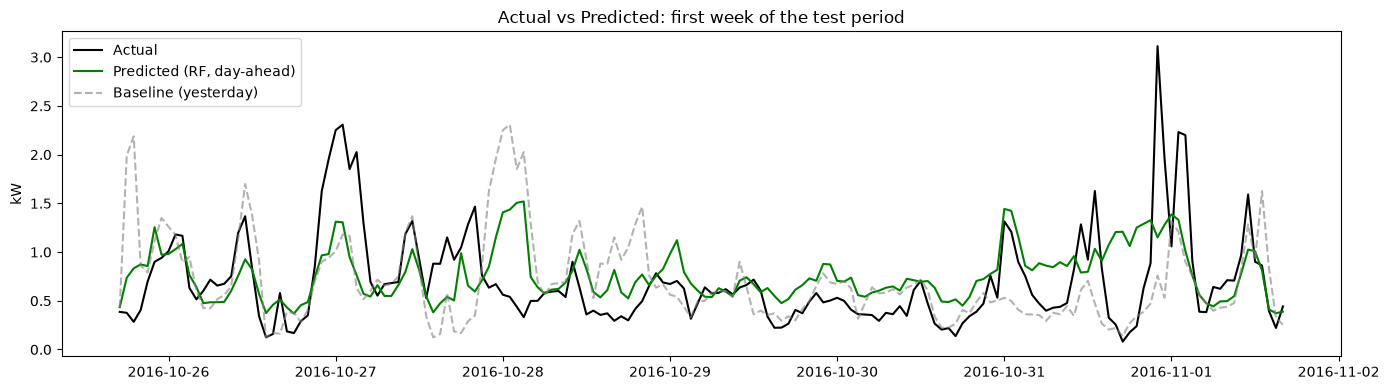

In [42]:
week = te.iloc[:168]
pred_week = m0.predict(week[f0])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week[TARGET], label="Actual", color="black")
ax.plot(week.index, pred_week, label="Predicted (RF, day-ahead)", color="green")
ax.plot(week.index, week["lag_24"], label="Baseline (yesterday)",
        color="gray", linestyle="--", alpha=0.6)
ax.set_ylabel("kW")
ax.set_title("Actual vs Predicted: first week of the test period")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "actual_vs_predicted_week.png", dpi=150)
plt.show()

## 💰 Cell 20 · Monthly Bill Estimate

Turns the forecast into an estimated electricity bill.

- Loads (or creates) `config.json` with the price tiers in EGP
- `monthly_bill()` → calculates the bill with tiered pricing
- Predicts 30 days of consumption and compares **predicted vs actual** kWh and bill, with the error % for each

In [43]:
CONFIG = OUT / "config.json"
DEFAULT_CFG = {
    "currency": "EGP",
    "tiers": [
        {"up_to_kwh": 50,   "price": 0.68},
        {"up_to_kwh": 100,  "price": 0.87},
        {"up_to_kwh": 200,  "price": 1.00},
        {"up_to_kwh": 350,  "price": 1.73},
        {"up_to_kwh": 650,  "price": 2.18},
        {"up_to_kwh": 1000, "price": 2.35},
        {"up_to_kwh": None, "price": 2.89},
    ],
}
if not CONFIG.exists():                      # الملف الموجود (وتعديلاتك عليه) ما بيتكتبش فوقه
    CONFIG.write_text(json.dumps(DEFAULT_CFG, indent=2))
cfg = json.loads(CONFIG.read_text())


def monthly_bill(kwh, tiers):
    """كل شريحة بتحسب الكيلوات اللي في نطاقها بس."""
    total, lower = 0.0, 0.0
    for t in tiers:
        upper = float("inf") if t["up_to_kwh"] is None else t["up_to_kwh"]
        total += max(0.0, min(kwh, upper) - lower) * t["price"]
        lower = upper
        if kwh <= upper:
            break
    return total


month = te.iloc[: 24 * 30]                       # 30 يوم
pred_kwh = m0.predict(month[f0]).sum()           # كل ساعة: kW × 1h = kWh
actual_kwh = month[TARGET].sum()

pred_bill = monthly_bill(pred_kwh, cfg["tiers"])
actual_bill = monthly_bill(actual_kwh, cfg["tiers"])

print(f"Predicted : {pred_kwh:8.1f} kWh -> {pred_bill:8.2f} {cfg['currency']}")
print(f"Actual    : {actual_kwh:8.1f} kWh -> {actual_bill:8.2f} {cfg['currency']}")
print(f"kWh error : {abs(pred_kwh - actual_kwh) / actual_kwh * 100:.1f}%")
print(f"Bill error: {abs(pred_bill - actual_bill) / actual_bill * 100:.1f}%")

Predicted :    557.8 kWh ->   890.04 EGP
Actual    :    563.3 kWh ->   901.95 EGP
kWh error : 1.0%
Bill error: 1.3%


## 💾 Cell 21 · Save the Forecast Model

Saves the model, its feature list, and the scikit-learn version to `forecast_model.joblib`, then prints the file size.

In [44]:
joblib.dump({"model": m0, "features": f0, "sklearn_version": sklearn.__version__},
            OUT / "forecast_model.joblib")
print(round((OUT / "forecast_model.joblib").stat().st_size / 1e6, 1), "MB")

12.9 MB


## 📝 Cell 22 · Write `predict.py`

Writes a standalone script that forecasts the **next 24 hours** of consumption.

- Loads the saved model and warns if the scikit-learn version is different
- Needs at least **192 hours** of hourly history
- Rebuilds the same features used in training for each future hour
- Can be run from the command line: `python predict.py history.csv`

In [45]:
%%writefile D:/Hass/energy/predict.py
"""predict.py: forecast the next 24 hours of household consumption.

Generated by 02_forecast.ipynb (the %%writefile cell). Edit it there, not here.

    python predict.py history.csv

The CSV needs the time as the first column, a use_HO column (kW), hourly rows
and at least 192 hours of history. It prints the next 24 hours of forecast (kW).
"""
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd

MODEL_PATH = Path(__file__).with_name("forecast_model.joblib")
MIN_HISTORY = 192   # roll_168 reaches back 191 hours from the first forecast hour


def predict(history, col="use_HO"):
    bundle = joblib.load(MODEL_PATH)
    model, feats = bundle["model"], bundle["features"]

    saved = bundle.get("sklearn_version")
    if saved:
        import sklearn
        if saved != sklearn.__version__:
            warnings.warn(f"model saved with scikit-learn {saved}, "
                          f"running {sklearn.__version__}")

    y = history[col] if isinstance(history, pd.DataFrame) else history
    y = y.astype(float).sort_index().asfreq("1h").ffill()
    if len(y) < MIN_HISTORY:
        raise ValueError(f"need at least {MIN_HISTORY} hours of history, got {len(y)}")

    h = pd.Timedelta(hours=1)
    idx = pd.date_range(y.index[-1] + h, periods=24, freq="1h")

    rows = []
    for t in idx:
        rows.append({
            "hour": t.hour,
            "weekday": t.day_of_week,
            "is_weekend": int(t.day_of_week >= 5),
            "lag_24": y.loc[t - 24 * h],
            "lag_48": y.loc[t - 48 * h],
            "lag_168": y.loc[t - 168 * h],
            "roll_24": y.loc[t - 47 * h: t - 24 * h].mean(),
            "roll_168": y.loc[t - 191 * h: t - 24 * h].mean(),
        })
    X = pd.DataFrame(rows, index=idx)[feats]
    return pd.Series(model.predict(X), index=idx, name="forecast_kW")


if __name__ == "__main__":
    if len(sys.argv) != 2:
        sys.exit("Usage: python predict.py history.csv")
    hist = pd.read_csv(sys.argv[1], index_col=0, parse_dates=True)
    print(predict(hist).round(3).to_string())

Overwriting D:/Hass/energy/predict.py


## ✅ Cell 23 · Verify `predict.py`

Imports the new script and forecasts from a cutoff time. Then checks that its output **matches the notebook model** (max difference < 1e-9), so we know the script behaves exactly like the notebook.

In [46]:
sys.path.insert(0, str(OUT))
import predict
importlib.reload(predict)

cut = pd.Timestamp("2016-11-30 23:00")
fc = predict.predict(df.loc[:cut, [TARGET]])

ref = pd.Series(m0.predict(te.loc[fc.index, f0]), index=fc.index)
diff = float((fc - ref).abs().max())
print("max diff vs notebook:", diff)
assert diff < 1e-9, "predict.py does not match the notebook"

max diff vs notebook: 4.440892098500626e-16
